# Import Libraries

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from bs4 import BeautifulSoup
from nltk.stem import WordNetLemmatizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.svm import LinearSVC


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


# Loading Dataset

In [63]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arunasivapragasam/donors-choose")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'donors-choose' dataset.
Path to dataset files: /kaggle/input/donors-choose


In [64]:
import os

print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "Preprocessed_DonorsChoose_dataset.csv"))


['Preprocessed_DonorsChoose_dataset.csv']


# Task 1: Data Exploration and Preparation

In [65]:
df.head()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


In [66]:
df.tail()

,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
109243,p048540,mr,mo,grades_prek_2,literacy_language_math_science,literature_writing_mathematics,0,1,59.98,8,privacy shields help promote independent thinking,welcome mr ramos 2nd grade classroom title 1 s...,students_need_privacy_partitions_help_focus_be...,0
109244,p166281,ms,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,0,1,846.32,4,technology classroom,every morning start day core values lead solel...,students_need_two_ipad_protective_cases_enhanc...,0
109245,p155633,mrs,nj,grades_prek_2,literacy_language_math_science,literacy_mathematics,3,1,239.96,4,2016 2017 beginning year basics,great group sharing caring students multi grad...,students_need_giant_comfy_pillows_order_help_r...,0
109246,p206114,mrs,ny,grades_3_5,health_sports_specialneeds,health_wellness_specialneeds,0,1,73.05,16,flexible seating inclusive classroom,students live small rural community classroom ...,students_need_flexible_seating_options_bean_ba...,0
109247,p191189,ms,va,grades_6_8,appliedlearning_math_science,college_careerprep_mathematics,0,1,109.90,5,classroom tech develop 21st century leaders,last time used math probably within last hour ...,students_need_opportunities_work_technology_or...,1


In [67]:
# Shape of the data
df.shape

(109248, 14)

In [68]:
# Column names
df.columns.tolist()

['id',
 'teacher_prefix',
 'school_state',
 'project_grade_category',
 'project_subject_categories',
 'project_subject_subcategories',
 'teacher_number_of_previously_posted_projects',
 'project_is_approved',
 'price',
 'quantity',
 'cleaned_titles',
 'cleaned_essays',
 'cleaned_summary',
 'isdigit_summary']

In [69]:
# Summary
df.describe()

,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,isdigit_summary
count,109248.000000,109248.000000,109248.000000,109248.000000,109248.000000
mean,11.153165,0.848583,298.119343,16.965610,0.144222
std,27.777154,0.358456,367.498030,26.182942,0.351317
min,0.000000,0.000000,0.660000,1.000000,0.000000
25%,0.000000,1.000000,104.310000,4.000000,0.000000
50%,2.000000,1.000000,206.220000,9.000000,0.000000
75%,9.000000,1.000000,379.000000,21.000000,0.000000
max,451.000000,1.000000,9999.000000,930.000000,1.000000


In [70]:
# Data types
df.dtypes

,0
id,object
teacher_prefix,object
school_state,object
project_grade_category,object
project_subject_categories,object
project_subject_subcategories,object
teacher_number_of_previously_posted_projects,int64
project_is_approved,int64
price,float64
quantity,int64


In [71]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109248 entries, 0 to 109247
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   id                                            109248 non-null  object 
 1   teacher_prefix                                109248 non-null  object 
 2   school_state                                  109248 non-null  object 
 3   project_grade_category                        109248 non-null  object 
 4   project_subject_categories                    109248 non-null  object 
 5   project_subject_subcategories                 109248 non-null  object 
 6   teacher_number_of_previously_posted_projects  109248 non-null  int64  
 7   project_is_approved                           109248 non-null  int64  
 8   price                                         109248 non-null  float64
 9   quantity                                      10

In [72]:
# Checking Duplicate values
df.duplicated().sum()

np.int64(0)

In [73]:
# Checking Missing Values
df.isna().sum()

,0
id,0
teacher_prefix,0
school_state,0
project_grade_category,0
project_subject_categories,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
project_is_approved,0
price,0
quantity,0


In [74]:
# Percentage of Missing Values
(df.isna().sum()/len(df)*100)

,0
id,0.00000
teacher_prefix,0.00000
school_state,0.00000
project_grade_category,0.00000
project_subject_categories,0.00000
project_subject_subcategories,0.00000
teacher_number_of_previously_posted_projects,0.00000
project_is_approved,0.00000
price,0.00000
quantity,0.00000


In [75]:
# Dropping missing values
df = df.dropna(subset=['cleaned_titles'])

In [76]:
df.isna().sum()

,0
id,0
teacher_prefix,0
school_state,0
project_grade_category,0
project_subject_categories,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
project_is_approved,0
price,0
quantity,0


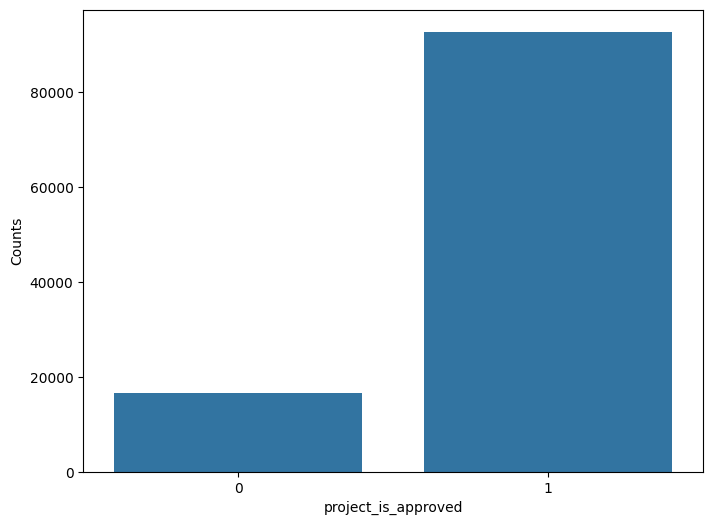

In [77]:
# Checking the class imbalance
values_grade = df['project_is_approved'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=values_grade.index, y=values_grade.values)

plt.xlabel("project_is_approved")
plt.ylabel("Counts")
plt.show()

# Task 2: NLP Preprocessing Pipeline

In [78]:
text_columns = [
    'cleaned_titles',
    'cleaned_essays',
    'cleaned_summary'
]

df[text_columns].head()

,cleaned_titles,cleaned_essays,cleaned_summary
0,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...
1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...
2,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...
3,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...
4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...


In [79]:
# Check missing values
print(df[text_columns].isnull().sum())

# Check empty strings
for col in text_columns:
    empty_count = df[col].fillna('').str.strip().eq('').sum()
    print(f"{col}: {empty_count} empty records")

cleaned_titles     0
cleaned_essays     0
cleaned_summary    0
dtype: int64
cleaned_titles: 0 empty records
cleaned_essays: 0 empty records
cleaned_summary: 0 empty records


In [80]:
stop_words = set(stopwords.words('english'))

# Preserve words that express negation
stop_words -= {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # Remove HTML tags
    text = BeautifulSoup(text, 'html.parser').get_text(' ')

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenize text
    tokens = word_tokenize(text)

    # Remove stop words and single-character tokens
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    # Lemmatize tokens
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return ' '.join(tokens)

In [81]:
for col in text_columns:
    df[col + '_processed'] = df[col].apply(preprocess_text)

df[[
    'cleaned_titles', 'cleaned_titles_processed',
    'cleaned_essays', 'cleaned_essays_processed',
    'cleaned_summary', 'cleaned_summary_processed'
]].head()

,cleaned_titles,cleaned_titles_processed,cleaned_essays,cleaned_essays_processed,cleaned_summary,cleaned_summary_processed
0,educational support english learners home,educational support english learner home,students english learners working english seco...,student english learner working english second...,students_need_opportunities_practice_beginning...,student need opportunity practice beginning re...
1,wanted projector hungry learners,wanted projector hungry learner,students arrive school eager learn polite gene...,student arrive school eager learn polite gener...,students_need_projector_help_viewing_education...,student need projector help viewing educationa...
2,soccer equipment awesome middle school students,soccer equipment awesome middle school student,true champions not always ones win guts mia ha...,true champion not always one win gut mia hamm ...,students_need_shine_guards_athletic_socks_socc...,student need shine guard athletic sock soccer ...
3,techie kindergarteners,techie kindergartener,work unique school filled esl english second l...,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,student need engage reading math way inspire m...
4,interactive math tools,interactive math tool,second grade classroom next year made around 2...,second grade classroom next year made around k...,students_need_hands_practice_mathematics_fun_p...,student need hand practice mathematics fun per...


In [82]:
processed_columns = [
    'cleaned_titles_processed',
    'cleaned_essays_processed',
    'cleaned_summary_processed'
]

df['combined_text'] = (
    df[processed_columns]
    .fillna('')
    .agg(' '.join, axis=1)
    .str.strip()
)

df[['combined_text', 'project_is_approved']].head()

,combined_text,project_is_approved
0,educational support english learner home stude...,0
1,wanted projector hungry learner student arrive...,1
2,soccer equipment awesome middle school student...,0
3,techie kindergartener work unique school fille...,1
4,interactive math tool second grade classroom n...,1


In [83]:
# Check missing and empty documents
print("Missing documents:", df['combined_text'].isna().sum())

print(
    "Empty documents:",
    df['combined_text'].str.strip().eq('').sum()
)

# Calculate token counts
df['token_count'] = df['combined_text'].str.split().str.len()

print("\nToken count statistics:")
print(df['token_count'].describe())

# Display an example
print("\nProcessed sample:")
print(df['combined_text'].iloc[0][:1000])

Missing documents: 0
Empty documents: 0

Token count statistics:
count    109205.000000
mean        151.737027
std          37.249426
min          73.000000
25%         123.000000
50%         143.000000
75%         172.000000
max         338.000000
Name: token_count, dtype: float64

Processed sample:
educational support english learner home student english learner working english second third language melting pot refugee immigrant native born american bringing gift language school language represented english learner program student every level mastery also country represented family within school student brings wealth knowledge experience u open eye new culture belief respect limit language limit world ludwig wittgenstein english learner strong support system home begs resource many time parent learning read speak english along side child sometimes creates barrier parent able help child learn phonetics letter recognition reading skill providing dvd player student able continue mastery

## Data Splitting

In [84]:
X = df.drop(columns='project_is_approved')
y = df['project_is_approved']

In [85]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42, test_size=0.4,stratify=y)

In [86]:
X = df['combined_text']
y = df['project_is_approved']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 65523
Testing samples: 43682


# Task 3: Embedding Approaches

## Implementing TF-IDF





In [87]:
# Unigram
tfidf_uni = TfidfVectorizer(
    ngram_range=(1, 1),
    max_features=30000,
    min_df=2
)

X_train_uni = tfidf_uni.fit_transform(X_train)
X_test_uni = tfidf_uni.transform(X_test)

print("Training shape:", X_train_uni.shape)
print("Testing shape:", X_test_uni.shape)

Training shape: (65523, 24877)
Testing shape: (43682, 24877)


Trying unigrams, bigrams and trigrams

In [88]:
ngram_results = {}

for name, ngram in {
    'Unigram': (1, 1),
    'Unigram + Bigram': (1, 2),
    'Unigram + Bigram + Trigram': (1, 3)
}.items():

    vectorizer = TfidfVectorizer(
        ngram_range=ngram,
        max_features=30000,
        min_df=2
    )

    X_train_temp = vectorizer.fit_transform(X_train)
    X_test_temp = vectorizer.transform(X_test)

    ngram_results[name] = {
        'vectorizer': vectorizer,
        'X_train': X_train_temp,
        'X_test': X_test_temp
    }

    print(f"\n{name}")
    print("Training shape:", X_train_temp.shape)
    print("Testing shape:", X_test_temp.shape)


Unigram
Training shape: (65523, 24877)
Testing shape: (43682, 24877)

Unigram + Bigram
Training shape: (65523, 30000)
Testing shape: (43682, 30000)

Unigram + Bigram + Trigram
Training shape: (65523, 30000)
Testing shape: (43682, 30000)


Using the unigram + bigram representation as our main TF-IDF representation:

In [89]:
tfidf_vectorizer = ngram_results['Unigram + Bigram']['vectorizer']

X_train_tfidf = ngram_results['Unigram + Bigram']['X_train']
X_test_tfidf = ngram_results['Unigram + Bigram']['X_test']

print("Final TF-IDF training shape:", X_train_tfidf.shape)
print("Final TF-IDF testing shape:", X_test_tfidf.shape)

Final TF-IDF training shape: (65523, 30000)
Final TF-IDF testing shape: (43682, 30000)


In [90]:
# Display vocabulary
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

# Display some words and their feature indices
list(tfidf_vectorizer.vocabulary_.items())[:20]

Vocabulary size: 30000


[('adhd', np.int64(687)),
 ('student', np.int64(24588)),
 ('need', np.int64(17019)),
 ('movement', np.int64(16748)),
 ('typical', np.int64(27647)),
 ('day', np.int64(6201)),
 ('classroom', np.int64(4337)),
 ('involves', np.int64(12897)),
 ('teaching', np.int64(26425)),
 ('entire', np.int64(8117)),
 ('not', np.int64(17822)),
 ('stay', np.int64(24198)),
 ('desk', np.int64(6544)),
 ('like', np.int64(14829)),
 ('would', np.int64(29575)),
 ('past', np.int64(19089)),
 ('want', np.int64(28496)),
 ('provide', np.int64(20406)),
 ('option', np.int64(18575)),
 ('comfortable', np.int64(5023))]

In [91]:
# Convert the first training document into a readable DataFrame
feature_names = tfidf_vectorizer.get_feature_names_out()

sample_vector = X_train_tfidf[0].toarray().flatten()

sample_df = pd.DataFrame({
    'Word': feature_names,
    'TF-IDF Score': sample_vector
})

sample_df = sample_df[sample_df['TF-IDF Score'] > 0]

sample_df.sort_values(
    by='TF-IDF Score',
    ascending=False
).head(15)

,Word,TF-IDF Score
24588,student,0.184850
6201,day,0.180106
6550,desk day,0.179606
17299,need movement,0.167263
12270,incentive,0.162097
1538,around classroom,0.150345
23303,sit still,0.145297
23273,sit,0.139537
687,adhd,0.138782
1563,around time,0.116005


## Implementing Word2Vec

In [92]:
!pip install -q gensim

Loading the embedding model

In [93]:
import gensim.downloader as api

glove_model = api.load('glove-wiki-gigaword-100')

print("Embedding dimensions:", glove_model.vector_size)
print("Vocabulary size:", len(glove_model))

Embedding dimensions: 100
Vocabulary size: 400000


Converting documents into word embeddings

In [94]:
def document_vector(text, model):

    words = text.split()

    # Keep words available in the embedding vocabulary
    vectors = [
        model[word]
        for word in words
        if word in model
    ]

    # Handle documents with no known words
    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    # Calculate average word embedding
    return np.mean(vectors, axis=0)

In [95]:
# Applying word embedding to training and testing data

X_train_w2v = np.array([
    document_vector(text, glove_model)
    for text in X_train
])

X_test_w2v = np.array([
    document_vector(text, glove_model)
    for text in X_test
])

print("Training shape:", X_train_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

Training shape: (65523, 100)
Testing shape: (43682, 100)


# Task 4 Classical Machine Learning Models

## Logistic Regression

In [96]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

Evaluate Logistic Regression

In [97]:
print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression Results
Accuracy: 0.7205714024083146
Precision: 0.9057237958491059
Recall: 0.7486782477341389
F1 Score: 0.8197471793963022

Classification Report:
              precision    recall  f1-score   support

           0       0.29      0.56      0.38      6610
           1       0.91      0.75      0.82     37072

    accuracy                           0.72     43682
   macro avg       0.60      0.66      0.60     43682
weighted avg       0.81      0.72      0.75     43682



### Visualize the Confusion Matrix

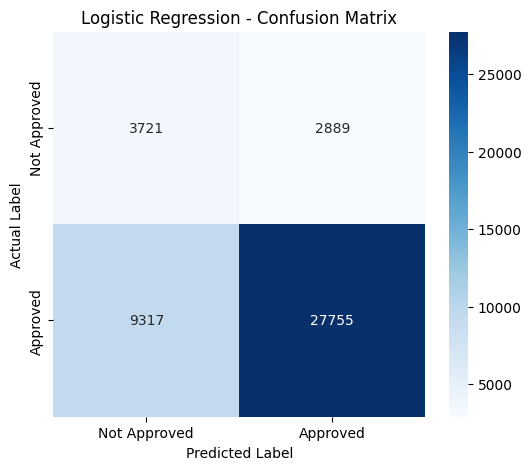

In [98]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Approved', 'Approved'],
    yticklabels=['Not Approved', 'Approved']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()

### Hyperparameter Tuning using Cross-Validation

Implement GridSearch

In [99]:
lr_params = {
    'C': [0.1, 1, 10]
}

lr_grid = GridSearchCV(
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),
    param_grid=lr_params,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_tfidf, y_train)

print("Best Parameters:", lr_grid.best_params_)
print("Best CV F1 Score:", lr_grid.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Parameters: {'C': 10}
Best CV F1 Score: 0.8492599057404195


Getting tuned model

In [100]:
best_lr = lr_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test_tfidf)

### Evaluation

In [101]:
print(classification_report(
    y_test,
    y_pred_lr_tuned,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.28      0.44      0.34      6610
           1       0.89      0.79      0.84     37072

    accuracy                           0.74     43682
   macro avg       0.58      0.62      0.59     43682
weighted avg       0.80      0.74      0.76     43682



## Support Vector Machine (SVM)

In [102]:
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=2000
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

Evaluate SVM

In [103]:
print("SVM Results")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_svm, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_svm, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

SVM Results
Accuracy: 0.7328876882926606
Precision: 0.8883928571428571
Recall: 0.7837181700474752
F1 Score: 0.8327791790873653

Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.45      0.34      6610
           1       0.89      0.78      0.83     37072

    accuracy                           0.73     43682
   macro avg       0.58      0.62      0.58     43682
weighted avg       0.79      0.73      0.76     43682



### Visulaize Confusion Matrix

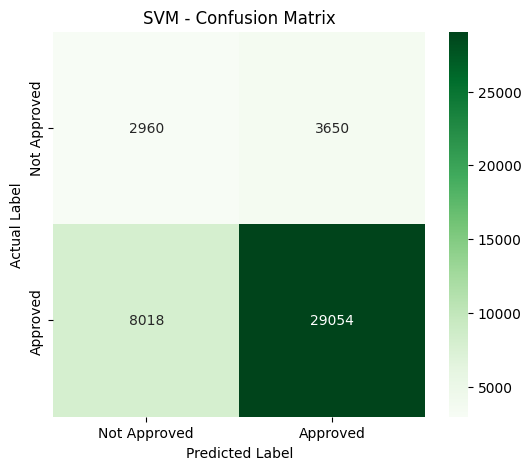

In [104]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Approved', 'Approved'],
    yticklabels=['Not Approved', 'Approved']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('SVM - Confusion Matrix')

plt.show()

### Hyperparameter Tuning

In [105]:
svm_params = {
    'C': [0.1, 1, 10]
}

svm_grid = GridSearchCV(
    LinearSVC(
        class_weight='balanced',
        random_state=42,
        max_iter=2000
    ),
    param_grid=svm_params,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train_tfidf, y_train)

print("Best Parameters:", svm_grid.best_params_)
print("Best CV F1 Score:", svm_grid.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Parameters: {'C': 10}
Best CV F1 Score: 0.8526775924173343


Retrieve the best model

In [106]:
best_svm = svm_grid.best_estimator_

y_pred_svm_tuned = best_svm.predict(X_test_tfidf)

print(classification_report(
    y_test,
    y_pred_svm_tuned,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.25      0.36      0.29      6610
           1       0.88      0.81      0.84     37072

    accuracy                           0.74     43682
   macro avg       0.56      0.58      0.57     43682
weighted avg       0.78      0.74      0.76     43682



## Logistic Regression VS SVM

In [107]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_svm_tuned)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr_tuned, zero_division=0),
        precision_score(y_test, y_pred_svm_tuned, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr_tuned, zero_division=0),
        recall_score(y_test, y_pred_svm_tuned, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr_tuned, zero_division=0),
        f1_score(y_test, y_pred_svm_tuned, zero_division=0)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.738931,0.888721,0.791487,0.837290
1,SVM,0.738680,0.875333,0.807024,0.839792


Visulaization

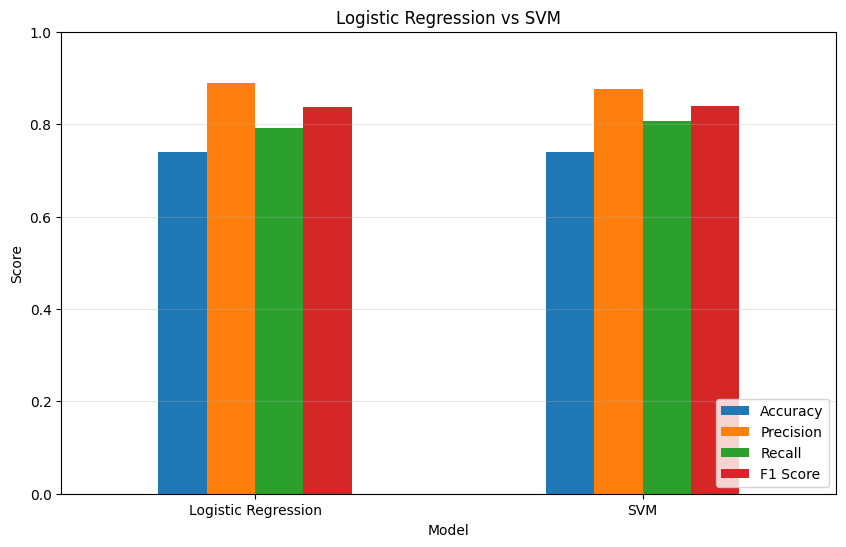

In [109]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title('Logistic Regression vs SVM')
plt.ylabel('Score')
plt.xlabel('Model')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

## ROC Curve and Precision-Recall Curve

### ROC Curve

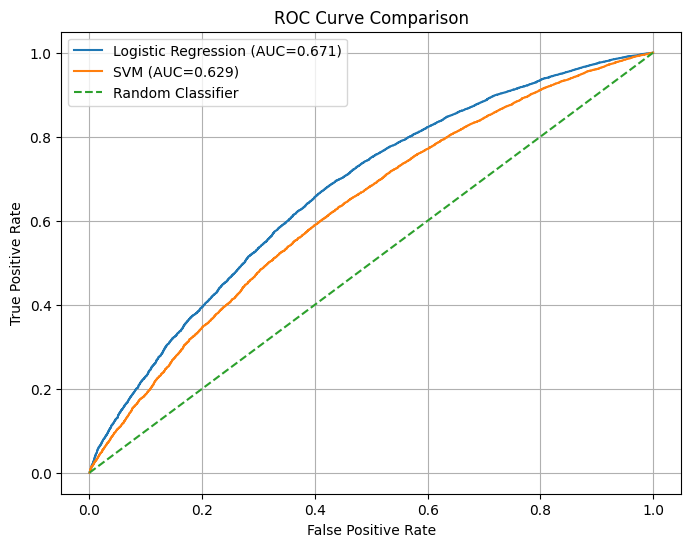

In [110]:
from sklearn.metrics import roc_curve, roc_auc_score

# Obtain decision scores
lr_scores = best_lr.decision_function(X_test_tfidf)
svm_scores = best_svm.decision_function(X_test_tfidf)

# Calculate ROC values
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_scores)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_scores)

# Calculate AUC
auc_lr = roc_auc_score(y_test, lr_scores)
auc_svm = roc_auc_score(y_test, svm_scores)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={auc_lr:.3f})')
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC={auc_svm:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()
plt.show()

### Precision-Recall Curve

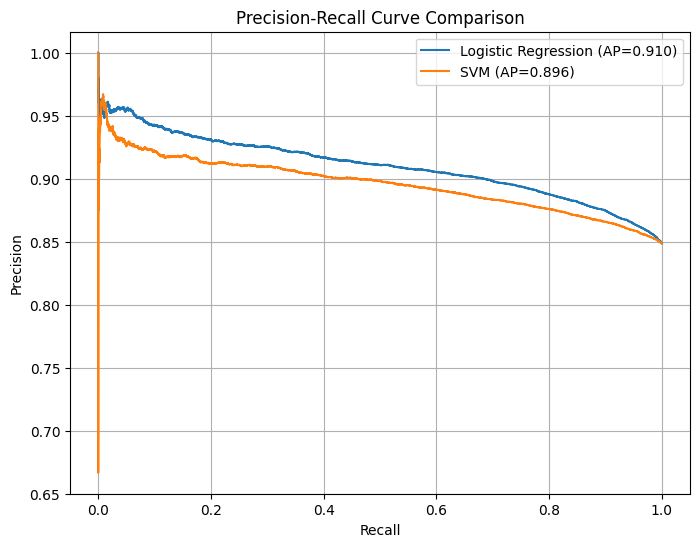

In [111]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_lr, recall_lr, _ = precision_recall_curve(y_test, lr_scores)
precision_svm, recall_svm, _ = precision_recall_curve(y_test, svm_scores)

ap_lr = average_precision_score(y_test, lr_scores)
ap_svm = average_precision_score(y_test, svm_scores)

plt.figure(figsize=(8, 6))

plt.plot(recall_lr, precision_lr, label=f'Logistic Regression (AP={ap_lr:.3f})')
plt.plot(recall_svm, precision_svm, label=f'SVM (AP={ap_svm:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')

plt.legend()
plt.grid()
plt.show()

# Task 5: Deep Learning Models

In [112]:
print(
    "Estimated TF-IDF training memory:",
    round(
        X_train_tfidf.shape[0] *
        X_train_tfidf.shape[1] * 4 / (1024**3),
        2
    ),
    "GB"
)

Estimated TF-IDF training memory: 7.32 GB


In [113]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(
    n_components=300,
    random_state=42
)

X_train_tfidf_reduced = svd.fit_transform(X_train_tfidf)
X_test_tfidf_reduced = svd.transform(X_test_tfidf)

print("Training shape:", X_train_tfidf_reduced.shape)
print("Testing shape:", X_test_tfidf_reduced.shape)

print(
    "Explained variance:",
    svd.explained_variance_ratio_.sum()
)

Training shape: (65523, 300)
Testing shape: (43682, 300)
Explained variance: 0.2417775799611701


In [114]:
X_train_tfidf_dl = X_train_tfidf_reduced.astype('float32')
X_test_tfidf_dl = X_test_tfidf_reduced.astype('float32')

X_train_w2v_dl = X_train_w2v.astype('float32')
X_test_w2v_dl = X_test_w2v.astype('float32')

y_train_dl = np.asarray(y_train).astype('float32')
y_test_dl = np.asarray(y_test).astype('float32')

In [115]:
print("TF-IDF:", X_train_tfidf_dl.shape)
print("GloVe:", X_train_w2v_dl.shape)
print("Target:", y_train_dl.shape)

TF-IDF: (65523, 300)
GloVe: (65523, 100)
Target: (65523,)


In [116]:
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Dense, Dropout, Concatenate, BatchNormalization

Brach1: TF-IDF input

In [117]:
# TF-IDF input
tfidf_input = Input(
    shape=(X_train_tfidf_dl.shape[1],),
    name='tfidf_input'
)

# Hidden layers
tfidf_branch = Dense(128, activation='relu')(tfidf_input)

tfidf_branch = BatchNormalization()(tfidf_branch)

tfidf_branch = Dropout(0.3)(tfidf_branch)

Branch 2: GloVe input

In [118]:
# GloVe input
w2v_input = Input(
    shape=(X_train_w2v_dl.shape[1],),
    name='w2v_input'
)

# Hidden layers
w2v_branch = Dense(64, activation='relu')(w2v_input)

w2v_branch = BatchNormalization()(w2v_branch)

w2v_branch = Dropout(0.3)(w2v_branch)

Merging both branches

In [119]:
# Combine both branches
merged = Concatenate()([tfidf_branch, w2v_branch])

Final Classification Layers

In [120]:
# Further feature learning
hidden = Dense(128, activation='relu')(merged)

hidden = Dropout(0.4)(hidden)

hidden = Dense(64, activation='relu')(hidden)

# Binary classification output
output = Dense(1, activation='sigmoid')(hidden)

Final model

In [121]:
model = Model(
    inputs=[tfidf_input, w2v_input],
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tfidf_input         │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ w2v_input           │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     38,528 │ tfidf_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      6,464 │ w2v_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 192)       │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     24,704 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      8,256 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         65 │ dense_5[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,785 (307.75 KB)

 Trainable params: 78,401 (306.25 KB)

 Non-trainable params: 384 (1.50 KB)

## Compile Model

In [122]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

## Handling class imbalance

In [123]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_dl)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_dl
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.float32(0.0): np.float64(3.304236006051437), np.float32(1.0): np.float64(0.5891508416055243)}


## Configuring callbacks

In [124]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

## Train the model

In [126]:
history = model.fit(
    x=[
        X_train_tfidf_dl,
        X_train_w2v_dl
    ],

    y=y_train_dl,

    epochs=30,

    batch_size=64,

    validation_split=0.2,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/30
820/820 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7113 - auc: 0.7751 - loss: 0.5690 - precision: 0.9283 - recall: 0.7149 - val_accuracy: 0.6791 - val_auc: 0.7217 - val_loss: 0.6071 - val_precision: 0.9178 - val_recall: 0.6835 - learning_rate: 2.5000e-04
Epoch 2/30
820/820 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7108 - auc: 0.7851 - loss: 0.5621 - precision: 0.9313 - recall: 0.7108
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
820/820 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.7129 - auc: 0.7818 - loss: 0.5619 - precision: 0.9299 - recall: 0.7156 - val_accuracy: 0.7185 - val_auc: 0.7207 - val_loss: 0.5633 - val_precision: 0.9124 - val_recall: 0.7398 - learning_rate: 2.5000e-04
Epoch 3/30
820/820 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7231 - auc: 0.7921 - loss: 0.5508 - precision: 0.9332 - recall: 0.7255 - val_accuracy: 0.6958 - val_auc: 0.7204 - val_loss: 0.5876 - val_precision: 0.9140 - val_recall: 0.7087 - learning_rate:

## Visualize training performance

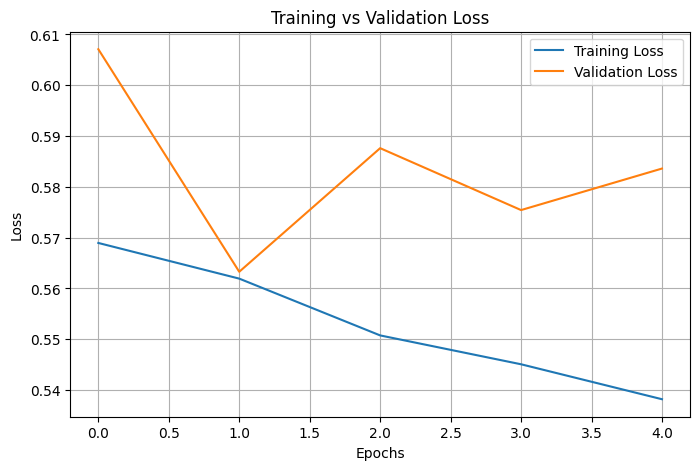

In [127]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

Accuracy

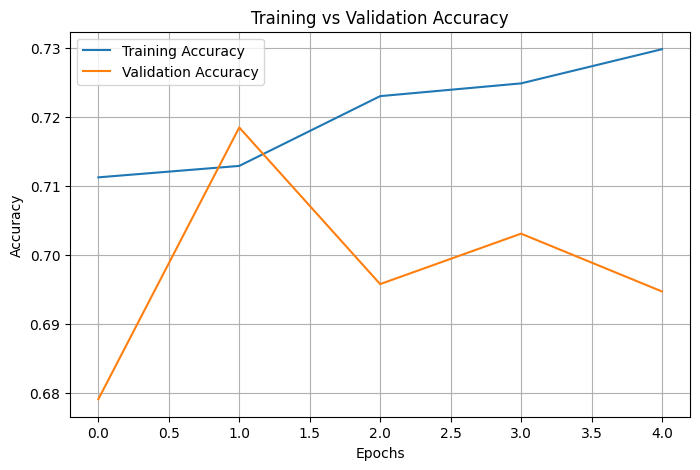

In [128]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.grid()
plt.show()

## Evaluating using test data

In [129]:
test_results = model.evaluate(
    [
        X_test_tfidf_dl,
        X_test_w2v_dl
    ],
    y_test_dl,
    verbose=1
)

print("\nTest Results:")

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

1366/1366 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6724 - auc: 0.7228 - loss: 0.6155 - precision: 0.9162 - recall: 0.6759

Test Results:
loss: 0.6155
compile_metrics: 0.6724


## Generate predictions

In [130]:
y_prob_dl = model.predict(
    [
        X_test_tfidf_dl,
        X_test_w2v_dl
    ]
)

print(y_prob_dl[:10])

1366/1366 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
[[0.7131316 ]
 [0.63440084]
 [0.36038703]
 [0.73967767]
 [0.4799002 ]
 [0.8244289 ]
 [0.4352775 ]
 [0.46968922]
 [0.5546591 ]
 [0.33268237]]


In [133]:
y_pred_dl = (y_prob_dl >= 0.5).astype(int).flatten()

## Calculate classification metrics

In [134]:
print("Deep Learning Model Results")

print("Accuracy:", accuracy_score(y_test_dl, y_pred_dl))

print("Precision:", precision_score(
    y_test_dl, y_pred_dl, zero_division=0
))

print("Recall:", recall_score(
    y_test_dl, y_pred_dl, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_dl, y_pred_dl, zero_division=0
))

print("\nClassification Report:")

print(classification_report(
    y_test_dl,
    y_pred_dl,
    zero_division=0
))

Deep Learning Model Results
Accuracy: 0.6724280023808433
Precision: 0.916157811985813
Recall: 0.6758739749676306
F1 Score: 0.7778829884664938

Classification Report:
              precision    recall  f1-score   support

         0.0       0.26      0.65      0.38      6610
         1.0       0.92      0.68      0.78     37072

    accuracy                           0.67     43682
   macro avg       0.59      0.66      0.58     43682
weighted avg       0.82      0.67      0.72     43682



## Confusion Matrix

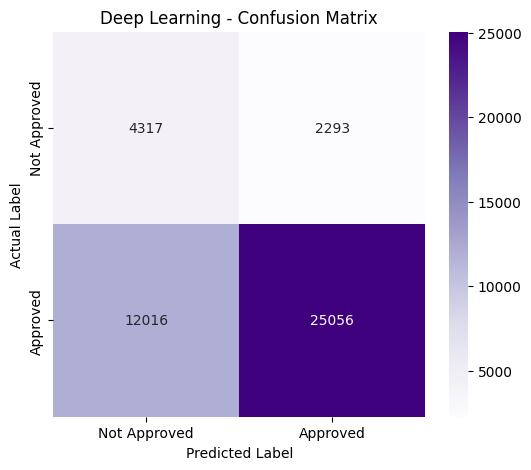

In [135]:
cm_dl = confusion_matrix(y_test_dl, y_pred_dl)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dl,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Not Approved', 'Approved'],
    yticklabels=['Not Approved', 'Approved']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Deep Learning - Confusion Matrix')

plt.show()

## ROC and Precision-Recall curves

ROC Curve

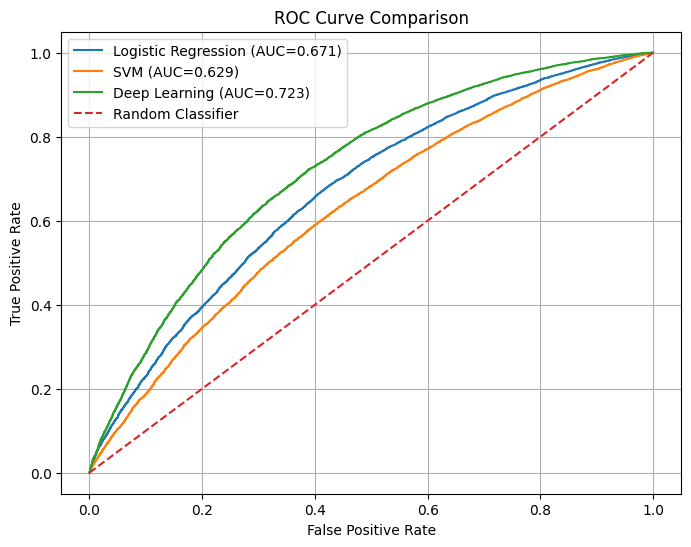

In [136]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_dl, tpr_dl, _ = roc_curve(y_test_dl, y_prob_dl.ravel())

auc_dl = roc_auc_score(y_test_dl, y_prob_dl.ravel())

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={auc_lr:.3f})')
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC={auc_svm:.3f})')
plt.plot(fpr_dl, tpr_dl, label=f'Deep Learning (AUC={auc_dl:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()
plt.show()

Precision-Recall curve

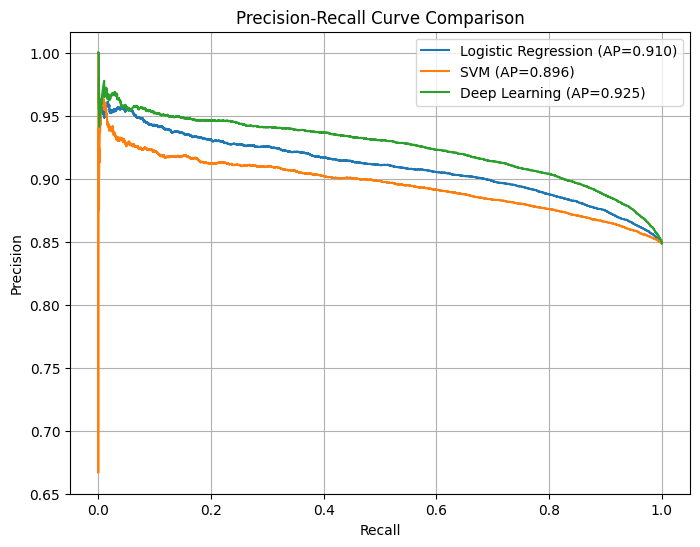

In [137]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_dl, recall_dl, _ = precision_recall_curve(
    y_test_dl,
    y_prob_dl.ravel()
)

ap_dl = average_precision_score(y_test_dl, y_prob_dl.ravel())

plt.figure(figsize=(8, 6))

plt.plot(recall_lr, precision_lr, label=f'Logistic Regression (AP={ap_lr:.3f})')
plt.plot(recall_svm, precision_svm, label=f'SVM (AP={ap_svm:.3f})')
plt.plot(recall_dl, precision_dl, label=f'Deep Learning (AP={ap_dl:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')

plt.legend()
plt.grid()
plt.show()

# Task 6: Model Comparison & Analysis

## Compare all 3 Models

In [138]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import numpy as np

# Generate predictions from the tuned classical ML models
y_pred_lr = best_lr.predict(X_test_tfidf)
y_pred_svm = best_svm.predict(X_test_tfidf)

# Deep learning predictions already generated in Task 5
# y_pred_dl and y_prob_dl

# Decision scores for classical ML models
y_score_lr = best_lr.decision_function(X_test_tfidf)
y_score_svm = best_svm.decision_function(X_test_tfidf)

# Probability scores for deep learning
y_score_dl = y_prob_dl.ravel()

# Function to calculate evaluation metrics
def evaluate_model(y_true, y_pred, y_score):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'PR-AUC': average_precision_score(y_true, y_score)
    }

# Compare all three models
results = {
    'Logistic Regression': evaluate_model(
        y_test, y_pred_lr, y_score_lr
    ),
    'Linear SVM': evaluate_model(
        y_test, y_pred_svm, y_score_svm
    ),
    'Deep Learning': evaluate_model(
        y_test, y_pred_dl, y_score_dl
    )
}

comparison_df = pd.DataFrame(results).T

comparison_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Logistic Regression,0.738931,0.888721,0.791487,0.837290,0.671321,0.909950
Linear SVM,0.738680,0.875333,0.807024,0.839792,0.629147,0.895705
Deep Learning,0.672428,0.916158,0.675874,0.777883,0.722771,0.924828


### Compare evaluation metrics

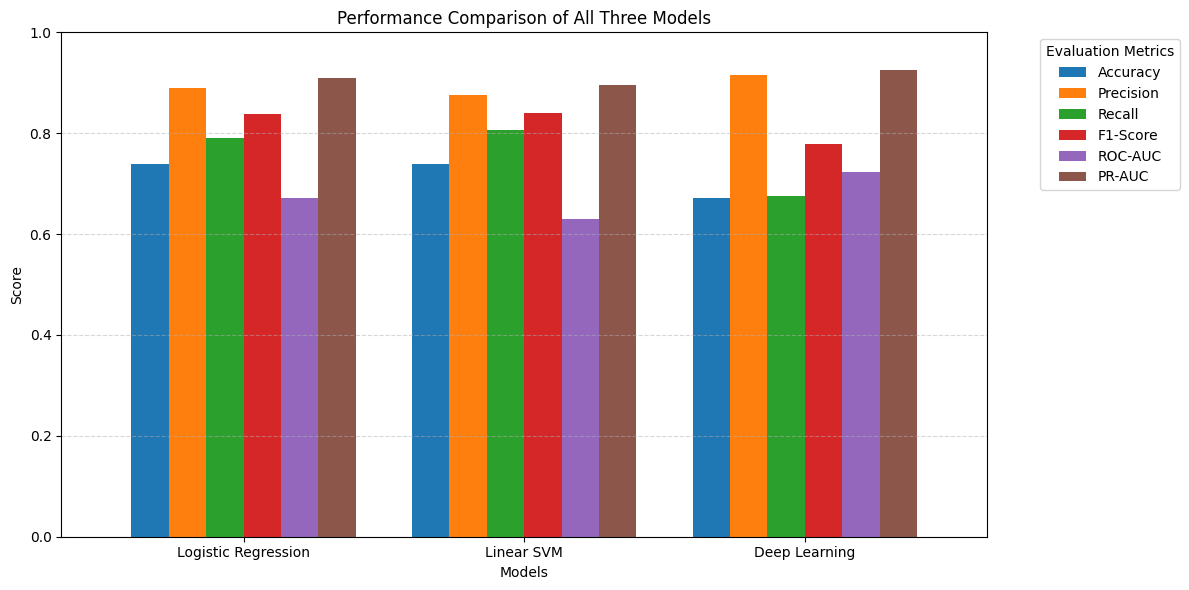

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison_df.plot(
    kind='bar',
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title('Performance Comparison of All Three Models')
plt.xlabel('Models')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics', bbox_to_anchor=(1.05, 1))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Compare ROC Curves

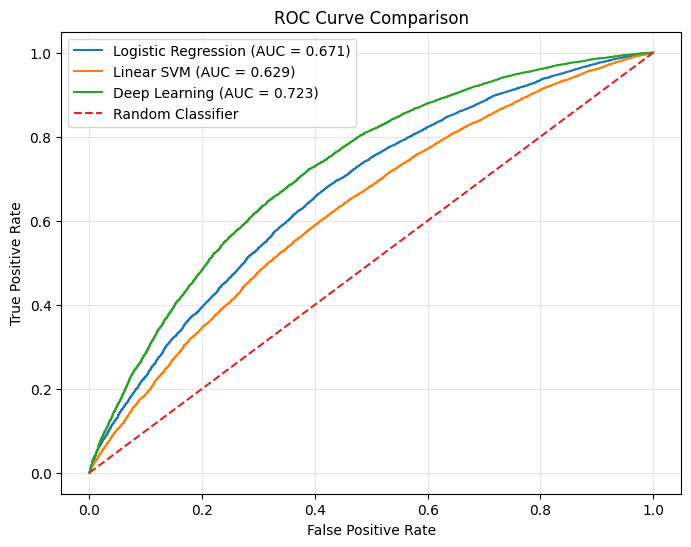

In [140]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve values
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_score_lr)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)
fpr_dl, tpr_dl, _ = roc_curve(y_test, y_score_dl)

# Plot all ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc(fpr_lr, tpr_lr):.3f})')
plt.plot(fpr_svm, tpr_svm, label=f'Linear SVM (AUC = {auc(fpr_svm, tpr_svm):.3f})')
plt.plot(fpr_dl, tpr_dl, label=f'Deep Learning (AUC = {auc(fpr_dl, tpr_dl):.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Compare Precision-Recall curves

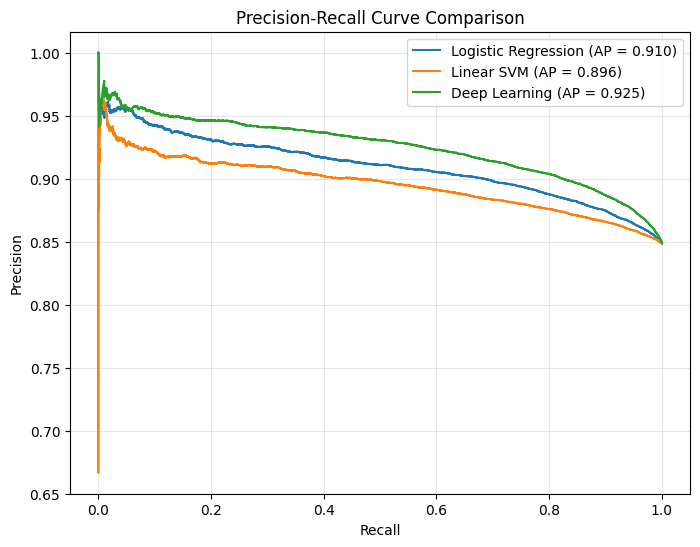

In [142]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision-recall values
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_score_lr)
precision_svm, recall_svm, _ = precision_recall_curve(y_test, y_score_svm)
precision_dl, recall_dl, _ = precision_recall_curve(y_test, y_score_dl)

# Plot all PR curves
plt.figure(figsize=(8, 6))

plt.plot(recall_lr, precision_lr,
         label=f'Logistic Regression (AP = {average_precision_score(y_test, y_score_lr):.3f})')

plt.plot(recall_svm, precision_svm,
         label=f'Linear SVM (AP = {average_precision_score(y_test, y_score_svm):.3f})')

plt.plot(recall_dl, precision_dl,
         label=f'Deep Learning (AP = {average_precision_score(y_test, y_score_dl):.3f})')

plt.title('Precision-Recall Curve Comparison')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Strengths and weaknesses summary

**Logistic Regression**

* **Strengths:** Simple, computationally efficient, and interpretable.
* **Weaknesses:** Limited ability to learn complex nonlinear patterns.


**Linear SVM**

* **Strengths**: Effective for high-dimensional text classification and sparse TF-IDF features.
* **Weaknesses:** Less interpretable and does not directly provide probability estimates.

**Deep Learning**

* **Strengths:** Combines TF-IDF and pretrained GloVe representations and learns nonlinear patterns.
* **Weaknesses:** Requires more computational resources, training time, and hyperparameter tuning.

## Best-Performing Model

In [144]:
best_f1_model = comparison_df['F1-Score'].idxmax()
best_auc_model = comparison_df['ROC-AUC'].idxmax()

print("Best model based on F1-Score:", best_f1_model)
print("Best model based on ROC-AUC:", best_auc_model)

print("\nHighest F1-Score:")
print(comparison_df['F1-Score'].max())

print("\nHighest ROC-AUC:")
print(comparison_df['ROC-AUC'].max())

Best model based on F1-Score: Linear SVM
Best model based on ROC-AUC: Deep Learning

Highest F1-Score:
0.8397917222214425

Highest ROC-AUC:
0.7227706382542505
